In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, os, json, time
sys.path.insert(0, os.path.abspath('..'))   # make `evqaoa` and `experiments` importable from notebooks/
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit.quantum_info import Statevector
from evqaoa import (build_qubo, objective_scales, qubo_to_hamiltonian, build_qaoa)
from experiments import scaling as sc

OUT = os.path.abspath('../results/03_scaling'); os.makedirs(OUT, exist_ok=True)
LAM = (0.5, 0.3, 0.2)                      # cost, peak, wear weights (same as the upstream notebook)
SIZES = [(3, 4), (4, 4), (4, 5), (4, 6), (5, 5)]   # (vehicles, slots)
RESTARTS, MAXITER = 6, 300                  # budget caps to keep the notebook fast
SOURCE_RESTARTS, SOURCE_MAXITER = 12, 500   # more effort for the 3x4 'source' angles
GATES = ['rz', 'sx', 'x', 'cx']
COL = {'transfer': '#0072B2', 'warm': '#E69F00', 'random': '#009E73', 'sim': '#CC79A7', 'qiskit': '#555555'}
T0 = time.time()

# 03 - System-size scaling and parameter transfer

**Why this notebook?** The first prototype solved one tiny problem (3 EVs, 4 time slots = 12 qubits). The organisers
suggest studying the *system size effect*: what happens to QAOA as the problem grows? Two future-work items from the
prototype are answered here:

1. **Larger instances** - 4x4 (16 qubits), 4x5 (20), 4x6 (24) and a bonus 5x5 (25 qubits).
2. **Parameter transfer** - QAOA has to *learn* its angles (beta, gamma) with a classical optimiser, and every
   evaluation costs a quantum circuit run. If angles learned on a cheap small instance also work on bigger ones, we
   save most of that cost.

**Workflow**
1. Define a family of instances (one qubit per vehicle-slot pair; every EV needs exactly 2 charging slots).
2. Simulate QAOA *exactly* with the XY mixer + Dicke start. These never leave the feasible schedules, so we simulate
   only the feasible subspace (e.g. 50,625 states for 4x6 instead of 2^24 = 16.8 million). We check this fast simulator
   against Qiskit's `Statevector` (unit tests + a timing comparison below).
3. Scaling study: quality, optimiser effort, simulation time, transpiled circuit size vs qubit count.
4. Transfer study: (a) 3x4 angles used directly, (b) 3x4 angles as warm start, (c) random-start optimisation.

*All metrics are for the feasible schedules only (the XY mixer keeps the feasible rate at 100%). Approximation ratio =
(worst - mean) / (worst - best) energy over feasible schedules: 1 is perfect. Picking a feasible schedule uniformly at random already scores about 0.66-0.71 (printed below as the 'uniform' baseline), so that is the bar QAOA must beat.*

## 1. The instance family
Prices follow a stylised overnight tariff: an expensive evening peak, a cheap night trough, rising again toward morning. Every vehicle needs 2 charging slots. Brute force only enumerates feasible schedules (a product of binomials), so the exact best/worst energies stay cheap.

In [3]:
rows, setups = [], {}
for V, T in SIZES:
    inst = sc.make_instance(V, T)
    scale = objective_scales(inst)
    Q, const = build_qubo(inst, LAM, scale)
    setups[(V, T)] = (inst, Q, const)
    n_feas = len(sc.feasible_basis(inst))
    rows.append(dict(name=f'{V}x{T}', V=V, T=T, qubits=inst.n, prices=list(inst.prices),
                     need=list(inst.need), feasible=n_feas, full_space=2 ** inst.n))
print(f"{'size':>5} {'qubits':>6} {'feasible':>9} {'2^n':>12}  prices")
for r in rows:
    print(f"{r['name']:>5} {r['qubits']:>6} {r['feasible']:>9,} {r['full_space']:>12,}  {r['prices']}")

 size qubits  feasible          2^n  prices
  3x4     12       216        4,096  [4, 1, 1, 3]
  4x4     16     1,296       65,536  [4, 1, 1, 3]
  4x5     20    10,000    1,048,576  [4, 2, 1, 1, 3]
  4x6     24    50,625   16,777,216  [4, 3, 1, 1, 2, 3]
  5x5     25   100,000   33,554,432  [4, 2, 1, 1, 3]


## 2. Sanity check: fast simulator vs Qiskit

Before trusting the subspace simulator, compare it with Qiskit's full `Statevector` on the circuit from `evqaoa.build_qaoa`
(random p=2 angles on 3x4). The difference should be at machine precision.

In [4]:
inst, Q, const = setups[(3, 4)]
H = qubo_to_hamiltonian(Q, const)
th = np.random.default_rng(5).uniform(0, np.pi, 4)
ref = Statevector(build_qaoa(inst, H, 2).assign_parameters(th)).expectation_value(H).real
fast = sc.make_simulator(inst, Q, const, 2).energy(th)
print(f'Qiskit Statevector: {ref:.12f}\nSubspace simulator: {fast:.12f}\n|difference| = {abs(ref-fast):.2e}')
assert abs(ref - fast) < 1e-9

Qiskit Statevector: 0.662502883317
Subspace simulator: 0.662502883317
|difference| = 2.55e-15


## 3. Scaling study (XY mixer + Dicke start, p = 1 and 2)

For each size and depth we run the optimiser from several random starts (COBYLA, capped budget) and record the
approximation ratio, P(optimal), the number of energy evaluations, and time per evaluation.

In [5]:
scaling = {}   # (size, p) -> dict
for (V, T) in SIZES:
    inst, Q, const = setups[(V, T)]
    for p in (1, 2):
        sim = sc.make_simulator(inst, Q, const, p)
        t_eval = sc.time_call(lambda: sim.energy(np.full(2 * p, 0.3)), repeats=5)
        run = sc.random_restarts(sim.energy, 2 * p, RESTARTS, MAXITER, seed=0)
        m = sc.metrics(sim, run['x'])
        scaling[(V, T, p)] = dict(size=f'{V}x{T}', qubits=inst.n, p=p, approx_ratio=m['approx_ratio'],
                                  p_optimal=m['p_optimal'], energy=m['energy'], e_best=m['e_best'],
                                  e_worst=m['e_worst'], e_mean_uniform=m['e_mean_uniform'],
                                  nfev=run['nfev'], sec_per_eval=t_eval, theta=run['x'].tolist(),
                                  ar_uniform=(m['e_worst']-m['e_mean_uniform'])/(m['e_worst']-m['e_best']),
                                  p_opt_uniform=float(np.isclose(sim.energies, m['e_best'], atol=1e-9).sum() / len(sim.energies)))
print(f"{'size':>5} {'q':>3} {'p':>2} {'approx':>7} {'AR unif.':>8} {'P(opt)':>8} {'P(opt) unif.':>12} {'evals':>6} {'ms/eval':>8}")
for k, r in scaling.items():
    print(f"{r['size']:>5} {r['qubits']:>3} {r['p']:>2} {r['approx_ratio']:>7.3f} {r['ar_uniform']:>8.3f} {r['p_optimal']:>8.4f} {r['p_opt_uniform']:>12.5f} {r['nfev']:>6} {1e3*r['sec_per_eval']:>8.2f}")

 size   q  p  approx AR unif.   P(opt) P(opt) unif.  evals  ms/eval
  3x4  12  1   0.741    0.670   0.0370      0.02778   1800     0.05
  3x4  12  2   0.864    0.670   0.1689      0.02778   1800     0.09
  4x4  16  1   0.740    0.704   0.0116      0.00926   1800     0.17
  4x4  16  2   0.887    0.704   0.1035      0.00926   1800     0.35
  4x5  20  1   0.718    0.700   0.0021      0.00120   1800     1.31
  4x5  20  2   0.766    0.700   0.0006      0.00120   1800     2.49
  4x6  24  1   0.670    0.657   0.0005      0.00047   1534     5.41
  4x6  24  2   0.803    0.657   0.0095      0.00047   1800    11.34
  5x5  25  1   0.728    0.711   0.0005      0.00030   1800    10.47
  5x5  25  2   0.769    0.711   0.0001      0.00030   1800    21.75


### Circuit size after transpiling

Transpiled to the generic basis `rz, sx, x, cx` (optimisation level 1). Two-qubit gates (`cx`) are what hurts on real hardware; this is the *all-to-all* count before any hardware routing, so real devices will need more.

In [6]:
circ_stats = {}
for (V, T) in SIZES:
    inst, Q, const = setups[(V, T)]
    H = qubo_to_hamiltonian(Q, const)
    for p in (1, 2):
        t0 = time.time()
        tq = transpile(build_qaoa(inst, H, p), basis_gates=GATES, optimization_level=1, seed_transpiler=0)
        circ_stats[(V, T, p)] = dict(size=f'{V}x{T}', qubits=inst.n, p=p, depth=tq.depth(),
                                     cx=int(tq.count_ops().get('cx', 0)), total_gates=int(sum(tq.count_ops().values())))
        print(f"{V}x{T} p={p}: depth {tq.depth():>5}, cx {circ_stats[(V,T,p)]['cx']:>5}  ({time.time()-t0:.1f}s to transpile)")

3x4 p=1: depth   106, cx    93  (0.5s to transpile)
3x4 p=2: depth   141, cx   153  (0.0s to transpile)
4x4 p=1: depth   115, cx   140  (0.0s to transpile)
4x4 p=2: depth   153, cx   236  (0.0s to transpile)
4x5 p=1: depth   161, cx   228  (0.0s to transpile)
4x5 p=2: depth   202, cx   352  (0.0s to transpile)
4x6 p=1: depth   302, cx   380  (0.0s to transpile)
4x6 p=2: depth   343, cx   532  (0.0s to transpile)
5x5 p=1: depth   170, cx   310  (0.0s to transpile)
5x5 p=2: depth   214, cx   490  (0.0s to transpile)


### Why the subspace trick matters: time per evaluation

Compare one energy evaluation with Qiskit's full `Statevector` (cost grows as 2^n) against the feasible-subspace simulator.
Qiskit is measured at 12, 16 and 20 qubits only. A 24-qubit run would need 16.8 M amplitudes per layer and was not
attempted (extrapolated cost from the 12-20 qubit trend: minutes per evaluation, and the optimiser needs hundreds).

In [7]:
qiskit_time = {}
for (V, T) in [(3, 4), (4, 4), (4, 5)]:
    inst, Q, const = setups[(V, T)]
    H = qubo_to_hamiltonian(Q, const)
    bound = build_qaoa(inst, H, 1).assign_parameters([0.3, 0.3])
    qiskit_time[inst.n] = sc.time_call(lambda: Statevector(bound).expectation_value(H), repeats=1 if inst.n >= 20 else 3)
    print(f"{inst.n} qubits: Qiskit Statevector {qiskit_time[inst.n]:.3f} s/eval  vs  subspace {scaling[(V,T,1)]['sec_per_eval']:.4f} s/eval")

12 qubits: Qiskit Statevector 0.009 s/eval  vs  subspace 0.0000 s/eval
16 qubits: Qiskit Statevector 0.039 s/eval  vs  subspace 0.0002 s/eval


20 qubits: Qiskit Statevector 2.542 s/eval  vs  subspace 0.0013 s/eval


## 4. Parameter transfer

Learn the best angles on the cheap 3x4 problem (p=1 and p=2, generous budget), then on each bigger instance compare

* **(a) Direct transfer** - use the 3x4 angles as they are: **1 evaluation**, no optimisation.
* **(b) Warm start** - run COBYLA starting at the 3x4 angles (single run).
* **(c) Random start** - the usual approach: several random-start COBYLA runs (budget from the scaling study).

*Target for "evaluations needed": reach 95% of the improvement that the random-start optimum achieves over a uniformly random feasible schedule, i.e. AR >= AR_uniform + 0.95 (AR_random - AR_uniform). (A plain '95% of the AR' target would be met by an untrained circuit, because uniform sampling already scores about 0.7.)* Evaluations of random start are counted across all restarts (that is what you actually pay).

In [8]:
source = {}
inst, Q, const = setups[(3, 4)]
for p in (1, 2):
    sim = sc.make_simulator(inst, Q, const, p)
    run = sc.random_restarts(sim.energy, 2 * p, SOURCE_RESTARTS, SOURCE_MAXITER, seed=123)
    source[p] = run['x']
    print(f'3x4 p={p}: angles (betas then gammas) = {np.round(run["x"], 4).tolist()}, '
          f'approx ratio {sc.metrics(sim, run["x"])["approx_ratio"]:.4f}')

transfer = {}
for (V, T) in SIZES:
    inst, Q, const = setups[(V, T)]
    for p in (1, 2):
        sim = sc.make_simulator(inst, Q, const, p)
        theta0 = sc.transfer_angles(source[p], p)
        rnd = sc.random_restarts(sim.energy, 2 * p, RESTARTS, MAXITER, seed=1)
        m_rnd = sc.metrics(sim, rnd['x'])
        e_best, e_worst = m_rnd['e_best'], m_rnd['e_worst']
        ar_unif = (e_worst - m_rnd['e_mean_uniform']) / (e_worst - e_best)
        target_ar = ar_unif + 0.95 * (m_rnd['approx_ratio'] - ar_unif)
        target_e = e_worst - target_ar * (e_worst - e_best)
        m_dir = sc.metrics(sim, theta0)
        warm = sc.run_cobyla(sim.energy, theta0, MAXITER)
        m_warm = sc.metrics(sim, warm['x'])
        transfer[(V, T, p)] = dict(
            size=f'{V}x{T}', qubits=inst.n, p=p, target_ar=target_ar, ar_uniform=ar_unif,
            ar_direct=m_dir['approx_ratio'], ar_warm=m_warm['approx_ratio'], ar_random=m_rnd['approx_ratio'],
            popt_direct=m_dir['p_optimal'], popt_warm=m_warm['p_optimal'], popt_random=m_rnd['p_optimal'],
            evals_direct=1 if m_dir['approx_ratio'] >= target_ar else None,
            evals_warm=sc.evals_to_reach(warm['trace'], target_e),
            evals_random=sc.evals_to_reach(rnd['trace'], target_e),
            nfev_warm_total=warm['nfev'], nfev_random_total=rnd['nfev'])
print(f"{'size':>5} {'p':>2} | {'AR direct':>9} {'AR warm':>8} {'AR random':>9} | evals to 95%: {'direct':>6} {'warm':>5} {'random':>6}")
for r in transfer.values():
    print(f"{r['size']:>5} {r['p']:>2} | {r['ar_direct']:>9.3f} {r['ar_warm']:>8.3f} {r['ar_random']:>9.3f} | {'':>14}{str(r['evals_direct']):>6} {str(r['evals_warm']):>5} {str(r['evals_random']):>6}")

3x4 p=1: angles (betas then gammas) = [2.8521, 6.0137], approx ratio 0.7319


3x4 p=2: angles (betas then gammas) = [2.8958, 0.677, 5.3243, 4.6635], approx ratio 0.8705


 size  p | AR direct  AR warm AR random | evals to 95%: direct  warm random
  3x4  1 |     0.732    0.767     0.719 |                    1     1    877
  3x4  2 |     0.871    0.878     0.865 |                    1     1    811
  4x4  1 |     0.741    0.774     0.732 |                    1     1    881
  4x4  2 |     0.891    0.903     0.891 |                    1     1   1563
  4x5  1 |     0.702    0.710     0.713 |                 None  None   1432
  4x5  2 |     0.763    0.783     0.780 |                 None    13    198
  4x6  1 |     0.675    0.693     0.672 |                    1     1    880
  4x6  2 |     0.737    0.808     0.804 |                 None    11     18
  5x5  1 |     0.709    0.717     0.724 |                 None  None   1420
  5x5  2 |     0.769    0.787     0.782 |                 None    16     62


## 5. Plots

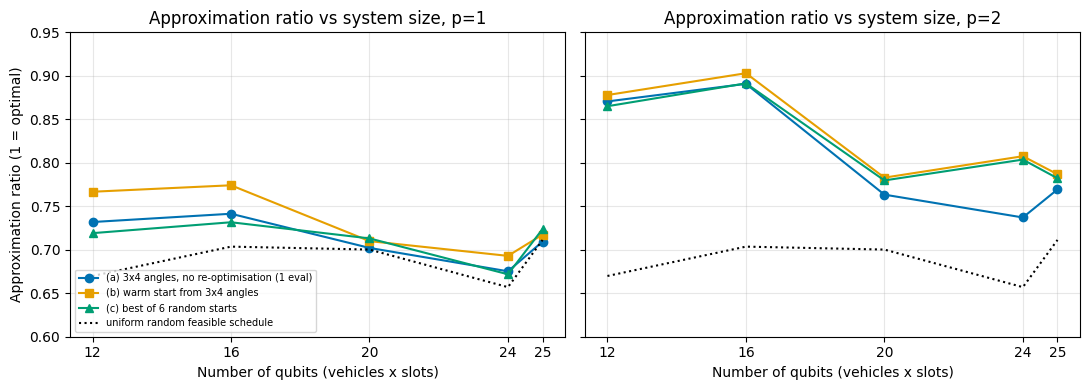

In [9]:
def sizes_for(p):
    return [transfer[(V, T, p)] for (V, T) in SIZES]

def save(fig, name):
    fig.tight_layout(); fig.savefig(f'{OUT}/{name}.png', dpi=140); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, p in zip(axes, (1, 2)):
    rs = sizes_for(p); q = [r['qubits'] for r in rs]
    ax.plot(q, [r['ar_direct'] for r in rs], 'o-', color=COL['transfer'], label='(a) 3x4 angles, no re-optimisation (1 eval)')
    ax.plot(q, [r['ar_warm'] for r in rs], 's-', color=COL['warm'], label='(b) warm start from 3x4 angles')
    ax.plot(q, [r['ar_random'] for r in rs], '^-', color=COL['random'], label=f'(c) best of {RESTARTS} random starts')
    ax.plot(q, [r['ar_uniform'] for r in rs], 'k:', label='uniform random feasible schedule')
    ax.set_title(f'Approximation ratio vs system size, p={p}'); ax.set_xlabel('Number of qubits (vehicles x slots)')
    ax.set_xticks(q); ax.set_ylim(0.6, 0.95); ax.grid(alpha=.3)
axes[0].set_ylabel('Approximation ratio (1 = optimal)'); axes[0].legend(fontsize=7, loc='lower left')
save(fig, 'approx_ratio_vs_qubits')

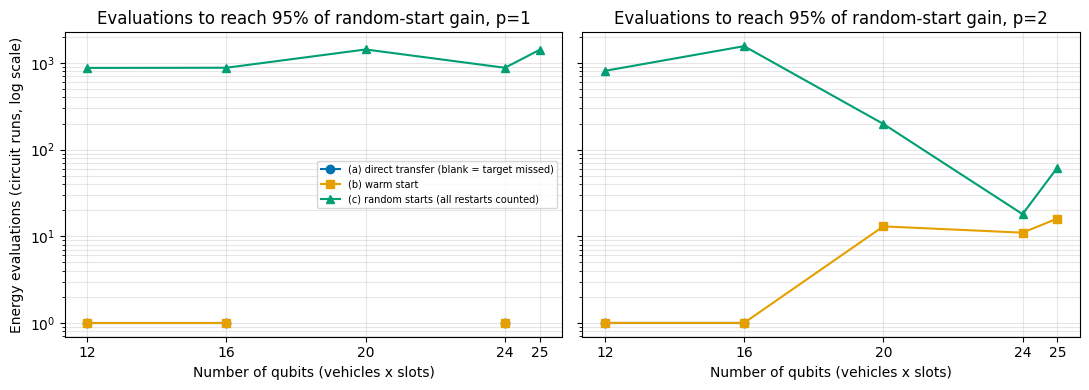

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, p in zip(axes, (1, 2)):
    rs = sizes_for(p); q = [r['qubits'] for r in rs]
    ev = lambda key: [np.nan if r[key] is None else r[key] for r in rs]
    ax.plot(q, ev('evals_direct'), 'o-', color=COL['transfer'], label='(a) direct transfer (blank = target missed)')
    ax.plot(q, ev('evals_warm'), 's-', color=COL['warm'], label='(b) warm start')
    ax.plot(q, ev('evals_random'), '^-', color=COL['random'], label='(c) random starts (all restarts counted)')
    ax.set_yscale('log'); ax.set_xticks(q); ax.grid(alpha=.3, which='both')
    ax.set_title(f'Evaluations to reach 95% of random-start gain, p={p}'); ax.set_xlabel('Number of qubits (vehicles x slots)')
axes[0].set_ylabel('Energy evaluations (circuit runs, log scale)'); axes[0].legend(fontsize=7)
save(fig, 'evaluations_vs_qubits')

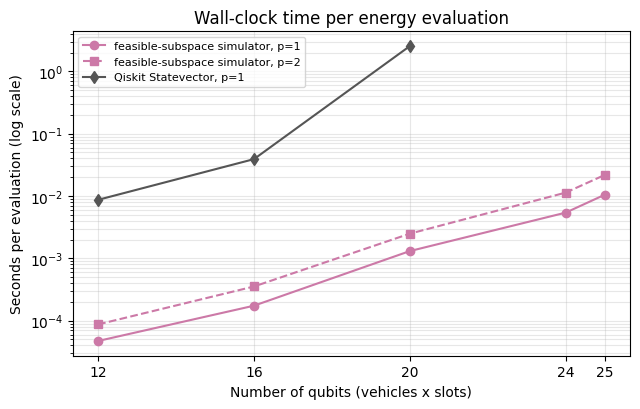

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
q_all = [scaling[(V, T, 1)]['qubits'] for V, T in SIZES]
for p, mk in ((1, 'o-'), (2, 's--')):
    ax.plot(q_all, [scaling[(V, T, p)]['sec_per_eval'] for V, T in SIZES], mk, color=COL['sim'], label=f'feasible-subspace simulator, p={p}')
ax.plot(list(qiskit_time), list(qiskit_time.values()), 'd-', color=COL['qiskit'], label='Qiskit Statevector, p=1')
ax.set_yscale('log'); ax.set_xticks(q_all); ax.grid(alpha=.3, which='both')
ax.set_title('Wall-clock time per energy evaluation'); ax.set_xlabel('Number of qubits (vehicles x slots)')
ax.set_ylabel('Seconds per evaluation (log scale)'); ax.legend(fontsize=8)
save(fig, 'time_per_eval_vs_qubits')

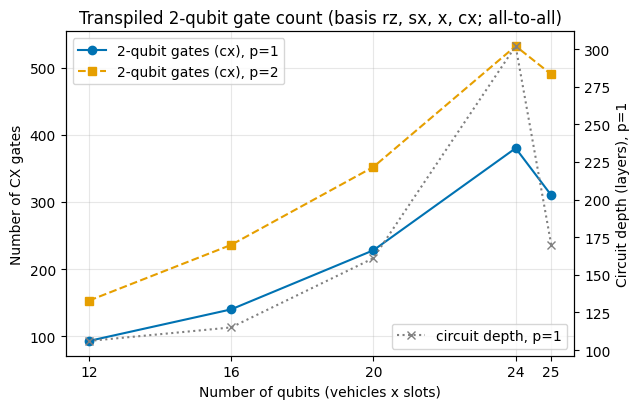

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for p, mk in ((1, 'o-'), (2, 's--')):
    ax.plot(q_all, [circ_stats[(V, T, p)]['cx'] for V, T in SIZES], mk, color=COL['transfer'] if p == 1 else COL['warm'], label=f'2-qubit gates (cx), p={p}')
ax.set_xticks(q_all); ax.grid(alpha=.3)
ax.set_title('Transpiled 2-qubit gate count (basis rz, sx, x, cx; all-to-all)'); ax.set_xlabel('Number of qubits (vehicles x slots)')
ax.set_ylabel('Number of CX gates'); ax.legend()
ax2 = ax.twinx(); ax2.plot(q_all, [circ_stats[(V, T, 1)]['depth'] for V, T in SIZES], 'x:', color='grey', label='circuit depth, p=1')
ax2.set_ylabel('Circuit depth (layers), p=1'); ax2.legend(loc='lower right')
save(fig, 'cx_count_vs_qubits')

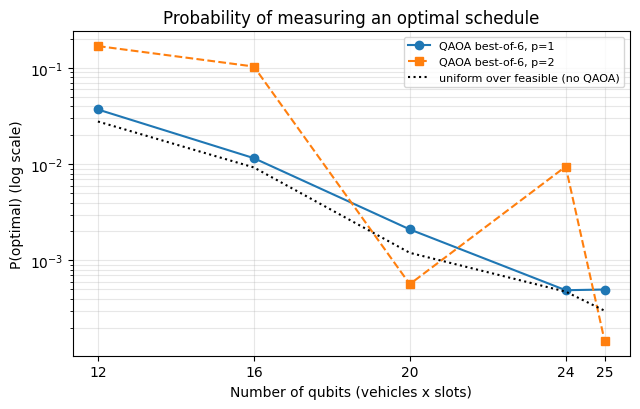

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for p, mk in ((1, 'o-'), (2, 's--')):
    ax.plot(q_all, [scaling[(V, T, p)]['p_optimal'] for V, T in SIZES], mk, label=f'QAOA best-of-{RESTARTS}, p={p}')
ax.plot(q_all, [scaling[(V, T, 1)]['p_opt_uniform'] for V, T in SIZES], 'k:', label='uniform over feasible (no QAOA)')
ax.set_yscale('log'); ax.set_xticks(q_all); ax.grid(alpha=.3, which='both')
ax.set_title('Probability of measuring an optimal schedule'); ax.set_xlabel('Number of qubits (vehicles x slots)')
ax.set_ylabel('P(optimal) (log scale)'); ax.legend(fontsize=8)
save(fig, 'p_optimal_vs_qubits')

In [14]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
result = clean(dict(config=dict(lam=LAM, restarts=RESTARTS, maxiter=MAXITER, source_restarts=SOURCE_RESTARTS,
                                source_maxiter=SOURCE_MAXITER, basis=GATES), instances=rows, scaling=scaling,
                    circuit=circ_stats, qiskit_statevector_sec=qiskit_time, source_angles={p: source[p].tolist() for p in source},
                    transfer=transfer))
json.dump(result, open(f'{OUT}/scaling_results.json', 'w'), indent=1)
print(f'saved to {OUT}; notebook compute time {time.time()-T0:.0f} s')

saved to /Users/sakxamshrestha/Desktop/IQ-hackathon/ev-qaoa-iq/results/03_scaling; notebook compute time 224 s


## Findings & limitations

(pending)